# CreditParity – Step 4
**Profitable, Fair Lending Decisions**

**Step 4:** Model comparison – logistic regression vs. random forest vs. XGBoost

## Step 4 · Model Comparison

**Goal.** In Steps 1–3 a simple logistic regression performed as well as gradient-boosted trees. Here we confirm this result with a broader comparison:
- **Logistic regression** (our baseline: transparent and easy to explain)
- **Random forest** (bagged decision trees)
- **XGBoost** (the model family that an initial analysis with IBM watsonx AutoAI selected as the best pipeline)

**Method.**
- **5-fold stratified cross-validation on the training set only** (4,000 applications). The test set (1,000 applications) stays untouched until the final evaluation, so that model selection and threshold selection (Step 5) cannot overfit to it. *Note:* the quick comparison in Step 3 used all 5,000 rows; here we are stricter.
- Every model gets the **same folds**, so the results are directly comparable fold by fold.
- **Metrics.** ROC AUC (threshold-independent ranking quality, our main criterion), recall and precision at the default threshold of 0.5, average precision (area under the precision–recall curve) and the Brier score (how well the predicted probabilities are calibrated, which matters because CreditParity shows the default probability to the user).
- Each model is tested twice: with **default settings** and **tuned** with a small hyperparameter search. Tuning uses *nested* cross-validation (the inner 3-fold search runs only on the training part of each outer fold), so the tuned scores are not optimistically biased.

**Decision rule.** We keep the logistic regression unless another model is *clearly and consistently* better, meaning a higher ROC AUC by more than the fold-to-fold variation **and** in (almost) every fold. For a high-risk use case such as credit scoring, explainability is worth a small loss in performance.

In [1]:
# Libraries
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier   # pre-installed in Google Colab; otherwise: pip install xgboost

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [2]:
# Load data
# In the repo the file lives in data/. In Google Colab, upload the CSV via the
# folder icon on the left and set DATA_PATH = "german_credit_data_biased_training.csv"
DATA_PATH = "../data/german_credit_data_biased_training.csv"
df = pd.read_csv(DATA_PATH)
df["y"] = (df["Risk"] == "Risk").astype(int)

X = df.drop(columns=["Risk", "y"])
y = df["y"]
categorical = X.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = X.select_dtypes(include="number").columns.tolist()

# Same stratified 80/20 split as in Step 3
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape,
      "| Default rate train:", round(y_train.mean(), 3))

Train: (4000, 20) | Test: (1000, 20) | Default rate train: 0.334


### The three models

All models use the same 20 features (including the sensitive ones; fairness follows in Step 6) and the same one-hot encoding for categorical features. Only the logistic regression needs standardized numeric features; tree models are insensitive to scaling.

In [3]:
def make_preprocessor(scale_numeric):
    """One-hot encoding for categories; optional standardization for numbers."""
    num_step = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", num_step, numeric),
    ])

def make_models():
    """Fresh, unfitted pipelines with default settings."""
    return {
        "Logistic regression": Pipeline([
            ("prep", make_preprocessor(scale_numeric=True)),
            ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
        "Random forest": Pipeline([
            ("prep", make_preprocessor(scale_numeric=False)),
            ("model", RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                             random_state=RANDOM_STATE))]),
        "XGBoost": Pipeline([
            ("prep", make_preprocessor(scale_numeric=False)),
            ("model", XGBClassifier(eval_metric="logloss", n_jobs=-1,
                                    random_state=RANDOM_STATE))]),
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"roc_auc": "roc_auc", "recall": "recall", "precision": "precision",
           "avg_precision": "average_precision", "brier": "neg_brier_score"}

def run_cv(models, label):
    """Cross-validate every model on the same folds; return summary and per-fold AUC."""
    summary, folds = [], {}
    for name, model in models.items():
        start = time.time()
        s = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING)
        folds[f"{name} ({label})"] = s["test_roc_auc"]
        summary.append({
            "Model": f"{name} ({label})",
            "ROC AUC": s["test_roc_auc"].mean(),
            "ROC AUC std": s["test_roc_auc"].std(),
            "Recall @0.5": s["test_recall"].mean(),
            "Precision @0.5": s["test_precision"].mean(),
            "Avg. precision": s["test_avg_precision"].mean(),
            "Brier score": -s["test_brier"].mean(),   # lower is better
            "Time (s)": time.time() - start,
        })
    return pd.DataFrame(summary).set_index("Model"), pd.DataFrame(folds)

### a) Default settings

In [4]:
default_summary, default_folds = run_cv(make_models(), "default")
default_summary.round(3)

,ROC AUC,ROC AUC std,Recall @0.5,Precision @0.5,Avg. precision,Brier score,Time (s)
Model,,,,,,,
Logistic regression (default),0.857,0.010,0.616,0.733,0.787,0.140,0.984
Random forest (default),0.844,0.007,0.562,0.788,0.771,0.143,6.293
XGBoost (default),0.829,0.010,0.593,0.687,0.748,0.163,2.002


### b) Tuned with nested cross-validation

A fair comparison should give the tree models a reasonable chance, so each model gets a small hyperparameter grid. The inner 3-fold grid search picks the settings by ROC AUC; the outer 5 folds measure performance on data that the search has never seen.

In [5]:
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

param_grids = {
    "Logistic regression": {"model__C": [0.01, 0.1, 1, 10]},
    "Random forest": {"model__max_depth": [None, 8, 12],
                      "model__min_samples_leaf": [1, 5, 10]},
    "XGBoost": {"model__max_depth": [2, 3, 4, 6],
                "model__learning_rate": [0.03, 0.1],
                "model__n_estimators": [200, 500]},
}

tuned_models = {name: GridSearchCV(model, param_grids[name], cv=inner_cv,
                                   scoring="roc_auc", n_jobs=-1)
                for name, model in make_models().items()}
tuned_summary, tuned_folds = run_cv(tuned_models, "tuned")
tuned_summary.round(3)

,ROC AUC,ROC AUC std,Recall @0.5,Precision @0.5,Avg. precision,Brier score,Time (s)
Model,,,,,,,
Logistic regression (tuned),0.856,0.010,0.617,0.737,0.787,0.140,7.881
Random forest (tuned),0.848,0.009,0.561,0.795,0.772,0.142,41.329
XGBoost (tuned),0.850,0.009,0.576,0.762,0.771,0.142,19.504


In [6]:
# Which settings does the search choose on the full training set?
for name, search in tuned_models.items():
    search.fit(X_train, y_train)
    print(f"{name:20s} best inner-CV AUC {search.best_score_:.3f} | {search.best_params_}")

Logistic regression  best inner-CV AUC 0.856 | {'model__C': 0.1}


Random forest        best inner-CV AUC 0.848 | {'model__max_depth': 12, 'model__min_samples_leaf': 5}


XGBoost              best inner-CV AUC 0.848 | {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 500}


### c) Side by side and fold by fold

In [7]:
comparison = pd.concat([default_summary, tuned_summary]).sort_values("ROC AUC", ascending=False)
comparison.round(3)

,ROC AUC,ROC AUC std,Recall @0.5,Precision @0.5,Avg. precision,Brier score,Time (s)
Model,,,,,,,
Logistic regression (default),0.857,0.010,0.616,0.733,0.787,0.140,0.984
Logistic regression (tuned),0.856,0.010,0.617,0.737,0.787,0.140,7.881
XGBoost (tuned),0.850,0.009,0.576,0.762,0.771,0.142,19.504
Random forest (tuned),0.848,0.009,0.561,0.795,0.772,0.142,41.329
Random forest (default),0.844,0.007,0.562,0.788,0.771,0.143,6.293
XGBoost (default),0.829,0.010,0.593,0.687,0.748,0.163,2.002


In [8]:
# Per-fold ROC AUC: is any model better in every fold, or only on average?
all_folds = pd.concat([default_folds, tuned_folds], axis=1)
all_folds.index = [f"Fold {i + 1}" for i in range(len(all_folds))]

ref = "Logistic regression (default)"
diff = all_folds.drop(columns=ref).sub(all_folds[ref], axis=0)
paired = pd.DataFrame({
    "Mean AUC diff. vs. logistic regression": diff.mean(),
    "Std of diff.": diff.std(),
    "Folds where better": (diff > 0).sum().astype(str) + " / 5",
}).round(3)
paired

,Mean AUC diff. vs. logistic regression,Std of diff.,Folds where better
Random forest (default),-0.012,0.004,0 / 5
XGBoost (default),-0.027,0.006,0 / 5
Logistic regression (tuned),-0.000,0.000,0 / 5
Random forest (tuned),-0.009,0.003,0 / 5
XGBoost (tuned),-0.007,0.003,0 / 5


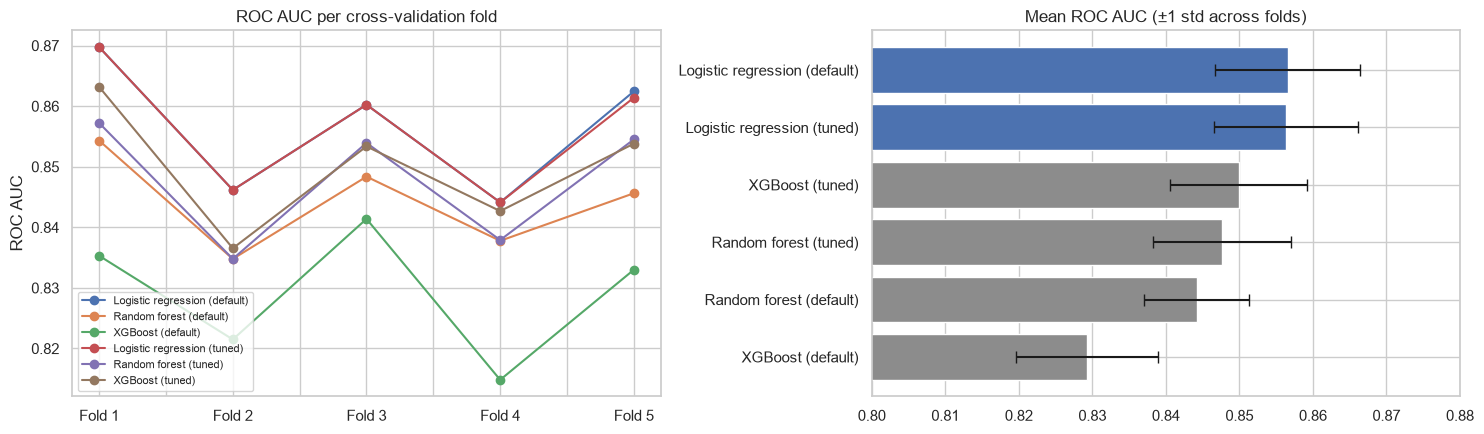

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Left: ROC AUC per fold for every model
all_folds.plot(marker="o", ax=axes[0])
axes[0].set_title("ROC AUC per cross-validation fold")
axes[0].set_ylabel("ROC AUC")
axes[0].legend(fontsize=8, loc="lower left")

# Right: mean ROC AUC with ±1 std across folds
order = comparison.sort_values("ROC AUC")
colors = ["#4C72B0" if "Logistic" in m else "#8C8C8C" for m in order.index]
axes[1].barh(order.index, order["ROC AUC"], xerr=order["ROC AUC std"],
             color=colors, capsize=4)
axes[1].set_xlim(0.80, 0.88)
axes[1].set_title("Mean ROC AUC (±1 std across folds)")
plt.tight_layout()
plt.show()

**Result.** The broader comparison confirms Step 3. The simple logistic regression has the **highest ROC AUC (0.857 ± 0.010)**, and it beats every tree model **in every one of the 5 folds**:

| Model (5-fold CV on training set) | ROC AUC | Recall @0.5 | Precision @0.5 | Brier score |
|---|---|---|---|---|
| Logistic regression (default) | **0.857** ± 0.010 | **0.616** | 0.733 | **0.140** |
| XGBoost (tuned) | 0.850 ± 0.009 | 0.576 | 0.762 | 0.142 |
| Random forest (tuned) | 0.848 ± 0.009 | 0.561 | 0.795 | 0.142 |
| Random forest (default) | 0.844 ± 0.007 | 0.562 | 0.788 | 0.143 |
| XGBoost (default) | 0.829 ± 0.010 | 0.593 | 0.687 | 0.163 |

**What we learn.**
- **Tuning helps the trees, but not enough.** Tuning lifts XGBoost from 0.829 to 0.850, yet it stays 0.007 below the logistic regression. With default settings, XGBoost is the weakest model and also the worst calibrated (Brier score 0.163).
- **The best XGBoost is a very shallow one.** The search picks trees of depth 2 with a small learning rate. Shallow boosted trees capture few interactions between features, which suggests that the relationships in this dataset are close to additive, exactly what a logistic regression models.
- **Tuning does not change the logistic regression** (0.857 vs. 0.856, best `C = 0.1`). We keep the default settings from Step 3.
- **Recall and precision at 0.5 are not a model choice.** The tree models show higher precision but lower recall at the default threshold of 0.5. These numbers only describe *one point* on each model's trade-off curve, and in Step 5 we move that point on purpose with a cost-based threshold. ROC AUC, which is independent of the threshold, is therefore the relevant criterion here.
- **Calibration.** The logistic regression also has the lowest Brier score, so its probabilities can be shown to the user directly as a default probability and mapped to rating classes.

**Decision for CreditParity.** No model is clearly and consistently better than the logistic regression. In fact, none is better at all. We therefore select the **logistic regression (one-hot encoding + standardization, default settings)** as the final model. It is just as accurate, faster, well calibrated and fully explainable, which matters for a high-risk AI system under the EU AI Act.

**How this relates to the initial AutoAI analysis.** AutoAI ranked pipelines by accuracy on a single 10% holdout and chose XGBoost. On a fair, repeated comparison with the same folds, the extra complexity does not pay off on this dataset.

**Limitations.** The dataset is synthetic, so the near-additive structure may not hold for real loan data, where tree models often have an edge. The hyperparameter grids are deliberately small. Fairness is not yet part of the comparison (Step 6).

**Next step.** Step 5: choose the cost-optimal threshold and the two zone boundaries of the three-zone policy, again with cross-validation on the training set only.
